# VMamba-Base fine-tuned: ImageNet weights → RDN full fine-tuning

This notebook contains its configuration, data checks, model construction, training loop, checkpoint resume, plots, and final test evaluation. It imports installed libraries only; no project helper scripts or external configuration files are needed. The four raw dataset files and published weights remain separate.

**Run one GPU notebook at a time.** To switch from an older notebook, finish or interrupt its current epoch, shut down its kernel, then open this notebook and use **Restart Kernel and Run All Cells**. Completed epochs can resume from the compatible saved run.

**This is a code-organization change.** Architecture, initialization, split, preprocessing, learning rates, and stopping settings are preserved. The earlier ViT convergence problems have not been silently changed. Save notebook edits before starting so code identity can be recorded.

## 1. Imports

Installed packages: PyTorch, torchvision, timm, NumPy, scikit-learn, matplotlib, Pillow, and tqdm.

In [1]:
from __future__ import annotations

import contextlib
import copy
import csv
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm


## 2. Settings

Review paths, epoch limit, patience, batch size, and learning rates here. The backbone and new head both train.

In [2]:
MODEL = 'vmamba_base'
NOTEBOOK_FILENAME = '09_vmamba_base_finetuned.ipynb'
# Change these paths if your notebook or dataset is stored elsewhere.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name in ("notebooks", "standalone_notebooks") else Path.cwd()
DATA_ROOT = Path(os.environ.get("RDN_DATA_ROOT", Path.home() / "Desktop" / "training_models"))
WEIGHTS_DIR = Path(os.environ.get("RDN_PRETRAINED_DIR", DATA_ROOT / "pretrained"))
NOTEBOOK_PATH = next((p for p in (
    PROJECT_DIR / "standalone_notebooks" / NOTEBOOK_FILENAME,
    Path.cwd() / NOTEBOOK_FILENAME,
    PROJECT_DIR / NOTEBOOK_FILENAME,
) if p.is_file()), PROJECT_DIR / "standalone_notebooks" / NOTEBOOK_FILENAME)

# None uses the same automatic run name as the original notebook.
# Give a new name when changing the recipe; existing runs are checked strictly.
RUN_NAME = None
RUN_TRAINING = True
RUN_FINAL_TEST = True
REQUIRE_CUDA = True

# Edit the values here. No external configuration file is loaded.
CONFIG = {'seed': 42,
 'max_epochs': 10,
 'early_stopping_patience': 7,
 'minimum_improvement': 0.0,
 'optimizer': 'AdamW',
 'learning_rate': 1e-05,
 'head_learning_rate': 0.0001,
 'weight_decay': 0.05,
 'label_smoothing': 0.0,
 'warmup_epochs': 2,
 'minimum_lr_ratio': 0.01,
 'gradient_clip_norm': 1.0,
 'precision': 'bf16',
 'num_workers': 0,
 'resume': True,
 'image_size': 224,
 'channels': 3,
 'normalization': 'imagenet',
 'interpolation': 'bilinear',
 'train_backbone': True,
 'require_fast_vmamba': True,
 'activation_checkpointing': True,
 'batch_size': 1,
 'accumulation_steps': 128,
 'feature_batch_size': 4,
 'initialization': 'pretrained',
 'model': 'vmamba_base',
 'architecture': 'vmamba_base_s2l15',
 'notes': 'Official ImageNet-1K pretrained VMamba-Base s2l15; all backbone layers train'}

print(f"{MODEL}: maximum {CONFIG['max_epochs']} epochs, patience {CONFIG['early_stopping_patience']}")
print("Effective batch:", CONFIG["batch_size"] * CONFIG["accumulation_steps"])


vmamba_base: maximum 10 epochs, patience 7
Effective batch: 128


## 3a. Runtime utilities

Device selection, precision, reproducibility, and atomic saving. Defining these functions does not start training.

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    temporary.replace(path)


def atomic_checkpoint(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def environment_info(device):
    packages = {}
    for name in ("torch", "torchvision", "timm", "numpy", "scikit-learn",
                 "matplotlib", "Pillow", "safetensors", "mamba-ssm", "triton"):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return {"python": platform.python_version(), "platform": platform.platform(),
            "packages": packages, "cuda_runtime": torch.version.cuda,
            "device": str(device),
            "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
            "gpu_memory_bytes": torch.cuda.get_device_properties(device).total_memory
            if device.type == "cuda" else None}


def select_device(require_cuda=True):
    if torch.cuda.is_available():
        device = torch.device("cuda")
        # Perform a tiny CUDA operation to catch wheels without this GPU's support.
        value = torch.ones(1, device=device) + 1
        if value.item() != 2:
            raise RuntimeError("CUDA check failed")
        return device
    if require_cuda:
        raise RuntimeError("CUDA is unavailable. Select the GPU environment/kernel; "
                           "use a CUDA-enabled Python environment. Training has not started.")
    return torch.device("cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # VMamba custom kernels may not have deterministic implementations.
    torch.use_deterministic_algorithms(True, warn_only=True)


def precision_context(device, precision):
    if device.type != "cuda" or precision == "fp32":
        return contextlib.nullcontext()
    if precision == "bf16":
        if not torch.cuda.is_bf16_supported():
            raise RuntimeError("BF16 is unsupported on this GPU; set precision='fp32' or 'fp16'.")
        dtype = torch.bfloat16
    elif precision == "fp16":
        dtype = torch.float16
    else:
        raise ValueError("precision must be bf16, fp16, or fp32")
    return torch.autocast(device_type="cuda", dtype=dtype)


## 3b. Check the dataset

Pin the original four file hashes, binary target, and fixed 97,200 / 10,800 / 3,000 split. Both validation classes are retained.

In [4]:
CLASS_NAMES = ["PeakBelow83", "PeakAtOrAbove83"]
EXPECTED_COUNTS = {"train": 97200, "validation": 10800, "test": 3000}
DATA_SHA256 = {'data/full_manifest.csv': '8b70f0ba4d746e9f504dd89ee03984602f725bfa9e3f359a1e82b46a9f2b0652',
 'data/images.npy': '4d9705401d6c2ca8c62da145506d5c2839c8a7285afd098b9c2fd575510df4da',
 'data/labels.npy': '8f58d927ca4199d703f6e8ada05597a86c50d86126c40ff94e878f7e58239638',
 'data/spectra.npy': '87168b2152ee172511a28da89648dec7366dece8e03310f91324a690819f62c9'}

def load_full_data(root):
    """Validate the exact packaged data, fixed target, and full split; no model evaluation."""
    root = Path(root)
    for name in ("data/images.npy", "data/labels.npy", "data/spectra.npy",
                 "data/full_manifest.csv"):
        actual = sha256_file(root / name)
        if actual != DATA_SHA256[name]:
            raise ValueError(f"File differs from the supplied full release: {name}")
    images = np.load(root / "data/images.npy", mmap_mode="r", allow_pickle=False)
    labels = np.load(root / "data/labels.npy", mmap_mode="r", allow_pickle=False)
    spectra = np.load(root / "data/spectra.npy", mmap_mode="r", allow_pickle=False)
    if images.shape != (111000, 16, 16) or labels.shape != (111000,) or spectra.shape != (111000, 128):
        raise ValueError("Expected the full 111,000-layout RDN release, not the pilot collection")
    if not np.isin(images, [0, 1]).all() or not np.isfinite(spectra).all():
        raise ValueError("Invalid image pixels or response values")
    if not np.array_equal(labels, (spectra.argmax(axis=1) >= 83).astype(np.int64)):
        raise ValueError("Labels must use the fixed compact-response cutoff at index 83")
    with (root / "data/full_manifest.csv").open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    if len(rows) != 111000 or [int(r["array_index"]) for r in rows] != list(range(111000)):
        raise ValueError("The full manifest must map every array index exactly once")
    if len({r["sample_id"] for r in rows}) != 111000:
        raise ValueError("Duplicate sample identifiers")
    if len({r["geometry_sha256"] for r in rows}) != 111000:
        raise ValueError("Duplicate geometries require a grouped split")
    partitions = {}
    for split, expected in EXPECTED_COUNTS.items():
        partition = [r for r in rows if r["split"] == split]
        if len(partition) != expected:
            raise ValueError(f"{split}: expected {expected} layouts, got {len(partition)}")
        indices = np.asarray([int(r["array_index"]) for r in partition], dtype=np.int64)
        expected_source = "test" if split == "test" else "train"
        if any(r["source_split"] != expected_source for r in partition):
            raise ValueError("Released test samples cannot enter training or validation")
        if not np.array_equal(labels[indices], np.asarray([int(r["label"]) for r in partition])):
            raise ValueError("Manifest labels disagree with label array")
        if split == "test" and not np.array_equal(indices, np.arange(108000, 111000)):
            raise ValueError("The original 3,000 released test samples must be preserved")
        if split != "test" and (indices >= 108000).any():
            raise ValueError("Test samples found in training/validation")
        partitions[split] = partition
    identity = {name: DATA_SHA256[name]
                for name in ("data/images.npy", "data/labels.npy", "data/spectra.npy",
                             "data/full_manifest.csv")}
    identity["target"] = "compact_response_argmax_ge_83_first_maximum"
    return partitions, identity


## 3c. Images and loaders

Resize the complete geometry, apply the recorded normalization, and build deterministic loaders. Only the training loader shuffles.

In [5]:
class LayoutDataset(Dataset):
    """Native arrays stay on disk; images are resized only when a sample is loaded."""
    def __init__(self, data_dir, rows, image_size, channels, normalization, interpolation="bilinear"):
        self.path = str(Path(data_dir) / "images.npy")
        self.rows = rows
        self.images = None
        self.channels = channels
        operations = [transforms.Resize((image_size, image_size),
                      interpolation={"bilinear": transforms.InterpolationMode.BILINEAR,
                                     "bicubic": transforms.InterpolationMode.BICUBIC}[interpolation]), transforms.ToTensor()]
        if normalization == "half":
            operations.append(transforms.Normalize([0.5] * channels, [0.5] * channels))
        elif normalization == "imagenet":
            if channels != 3:
                raise ValueError("ImageNet normalization requires three channels")
            operations.append(transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]))
        elif normalization != "none":
            raise ValueError(normalization)
        self.transform = transforms.Compose(operations)

    def __len__(self):
        return len(self.rows)

    def __getstate__(self):
        state = self.__dict__.copy()
        state["images"] = None  # Windows/WSL workers reopen the memory map.
        return state

    def __getitem__(self, index):
        if self.images is None:
            self.images = np.load(self.path, mmap_mode="r", allow_pickle=False)
        row = self.rows[index]
        image = Image.fromarray(self.images[int(row["array_index"])] * np.uint8(255))
        if self.channels == 3:
            image = image.convert("RGB")
        return self.transform(image), int(row["label"]), row["sample_id"]


def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)


def make_loader(dataset, batch_size, shuffle, seed, workers, device):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=device.type == "cuda",
                      persistent_workers=False, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed), drop_last=False)


def layout_dataset(root, rows, config):
    return LayoutDataset(Path(root) / "data", rows, config["image_size"],
                         config["channels"], config["normalization"], config.get("interpolation", "bilinear"))

def build_training_loaders(model, root, partitions, config, device, identity):
    # Recompute the backbone on every step: this is full fine-tuning.
    datasets = {
        split: layout_dataset(root, partitions[split], config)
        for split in ("train", "validation")
    }
    model.to(device)
    loaders = {
        split: make_loader(
            datasets[split], config["batch_size"], split == "train",
            config["seed"], config["num_workers"], device,
        )
        for split in ("train", "validation")
    }
    return model, loaders, False


### VMamba attribution

Adapted from [the official VMamba implementation](https://github.com/MzeroMiko/VMamba). Unused profiling, benchmarks, and Triton cross-scan kernels are omitted; this experiment uses the PyTorch cross-scan path.

```text
MIT License

Copyright (c) 2024 MzeroMiko

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```

## 4a. VMamba scan operations

PyTorch cross-scan/merge and their backward passes. The original MIT license is included below.

In [6]:
from collections import OrderedDict
from functools import partial
from typing import Any, Callable, Optional
import warnings

import torch.nn.functional as F
import torch.utils.checkpoint as checkpoint
from timm.layers import DropPath, trunc_normal_

try:
    import selective_scan_cuda
    WITH_SELECTIVESCAN_MAMBA = True
except ImportError:
    WITH_SELECTIVESCAN_MAMBA = False

def cross_scan_fwd(x: torch.Tensor, in_channel_first=True, out_channel_first=True, scans=0):
    if in_channel_first:
        B, C, H, W = x.shape
        if scans == 0:
            y = x.new_empty((B, 4, C, H * W))
            y[:, 0, :, :] = x.flatten(2, 3)
            y[:, 1, :, :] = x.transpose(dim0=2, dim1=3).flatten(2, 3)
            y[:, 2:4, :, :] = torch.flip(y[:, 0:2, :, :], dims=[-1])
        elif scans == 1:
            y = x.view(B, 1, C, H * W).repeat(1, 4, 1, 1)
        elif scans == 2:
            y = x.view(B, 1, C, H * W).repeat(1, 2, 1, 1)
            y = torch.cat([y, y.flip(dims=[-1])], dim=1)
        elif scans == 3:
            y = x.new_empty((B, 4, C, H * W))
            y[:, 0, :, :] = x.flatten(2, 3)
            y[:, 1, :, :] = torch.rot90(x, 1, dims=(2, 3)).flatten(2, 3)
            y[:, 2, :, :] = torch.rot90(x, 2, dims=(2, 3)).flatten(2, 3)
            y[:, 3, :, :] = torch.rot90(x, 3, dims=(2, 3)).flatten(2, 3)
    else:
        B, H, W, C = x.shape
        if scans == 0:
            y = x.new_empty((B, H * W, 4, C))
            y[:, :, 0, :] = x.flatten(1, 2)
            y[:, :, 1, :] = x.transpose(dim0=1, dim1=2).flatten(1, 2)
            y[:, :, 2:4, :] = torch.flip(y[:, :, 0:2, :], dims=[1])
        elif scans == 1:
            y = x.view(B, H * W, 1, C).repeat(1, 1, 4, 1)
        elif scans == 2:
            y = x.view(B, H * W, 1, C).repeat(1, 1, 2, 1)
            y = torch.cat([y, y.flip(dims=[1])], dim=2)
        elif scans == 3:
            y = x.new_empty((B, H * W, 4, C))
            y[:, :, 0, :] = x.flatten(1, 2)
            y[:, :, 1, :] = torch.rot90(x, 1, dims=(1, 2)).flatten(1, 2)
            y[:, :, 2, :] = torch.rot90(x, 2, dims=(1, 2)).flatten(1, 2)
            y[:, :, 3, :] = torch.rot90(x, 3, dims=(1, 2)).flatten(1, 2)

    if in_channel_first and (not out_channel_first):
        y = y.permute(0, 3, 1, 2).contiguous()
    elif (not in_channel_first) and out_channel_first:
        y = y.permute(0, 2, 3, 1).contiguous()

    return y


def cross_merge_fwd(y: torch.Tensor, in_channel_first=True, out_channel_first=True, scans=0):
    if out_channel_first:
        B, K, D, H, W = y.shape
        y = y.view(B, K, D, -1)
        if scans == 0:
            y = y[:, 0:2] + y[:, 2:4].flip(dims=[-1]).view(B, 2, D, -1)
            y = y[:, 0] + y[:, 1].view(B, -1, W, H).transpose(dim0=2, dim1=3).contiguous().view(B, D, -1)
        elif scans == 1:
            y = y.sum(1)
        elif scans == 2:
            y = y[:, 0:2] + y[:, 2:4].flip(dims=[-1]).view(B, 2, D, -1)
            y = y.sum(1)
        elif scans == 3:
            oy = y[:, 0, :, :].contiguous().view(B, D, -1)
            oy = oy + torch.rot90(y.view(B, K, D, W, H)[:, 1, :, :, :], -1, dims=(2, 3)).flatten(2, 3)
            oy = oy + torch.rot90(y.view(B, K, D, H, W)[:, 2, :, :, :], -2, dims=(2, 3)).flatten(2, 3)
            oy = oy + torch.rot90(y.view(B, K, D, W, H)[:, 3, :, :, :], -3, dims=(2, 3)).flatten(2, 3)
            y = oy
    else:
        B, H, W, K, D = y.shape
        y = y.view(B, -1, K, D)
        if scans == 0:
            y = y[:, :, 0:2] + y[:, :, 2:4].flip(dims=[1]).view(B, -1, 2, D)
            y = y[:, :, 0] + y[:, :, 1].view(B, W, H, -1).transpose(dim0=1, dim1=2).contiguous().view(B, -1, D)        
        elif scans == 1:
            y = y.sum(2)
        elif scans == 2:
            y = y[:, :, 0:2] + y[:, :, 2:4].flip(dims=[1]).view(B, -1, 2, D)
            y = y.sum(2)
        elif scans == 3:
            oy = y[:, :, 0, :].contiguous().view(B, -1, D)
            oy = oy + torch.rot90(y.view(B, W, H, K, D)[:, :, :, 1, :], -1, dims=(1, 2)).flatten(1, 2)
            oy = oy + torch.rot90(y.view(B, H, W, K, D)[:, :, :, 2, :], -2, dims=(1, 2)).flatten(1, 2)
            oy = oy + torch.rot90(y.view(B, W, H, K, D)[:, :, :, 3, :], -3, dims=(1, 2)).flatten(1, 2)
            y = oy

    if in_channel_first and (not out_channel_first):
        y = y.permute(0, 2, 1).contiguous()
    elif (not in_channel_first) and out_channel_first:
        y = y.permute(0, 2, 1).contiguous()

    return y


def cross_scan1b1_fwd(x: torch.Tensor, in_channel_first=True, out_channel_first=True, scans=0):
    if in_channel_first:
        B, _, C, H, W = x.shape
        if scans == 0:
            y = torch.stack([
                x[:, 0].flatten(2, 3),
                x[:, 1].transpose(dim0=2, dim1=3).flatten(2, 3),
                torch.flip(x[:, 2].flatten(2, 3), dims=[-1]),
                torch.flip(x[:, 3].transpose(dim0=2, dim1=3).flatten(2, 3), dims=[-1]),
            ], dim=1)
        elif scans == 1:
            y = x.flatten(2, 3)
        elif scans == 2:
            y = torch.stack([
                x[:, 0].flatten(2, 3),
                x[:, 1].flatten(2, 3),
                torch.flip(x[:, 2].flatten(2, 3), dims=[-1]),
                torch.flip(x[:, 3].flatten(2, 3), dims=[-1]),
            ], dim=1)
        elif scans == 3:
            y = torch.stack([
                x[:, 0, :, :, :].flatten(2, 3),
                torch.rot90(x[:, 1, :, :, :], 1, dims=(2, 3)).flatten(2, 3),
                torch.rot90(x[:, 2, :, :, :], 2, dims=(2, 3)).flatten(2, 3),
                torch.rot90(x[:, 3, :, :, :], 3, dims=(2, 3)).flatten(2, 3),
            ], dim=1)

    else:
        B, H, W, _, C = x.shape
        if scans == 0:
            y = torch.stack([
                x[:, :, :, 0].flatten(1, 2),
                x[:, :, :, 1].transpose(dim0=1, dim1=2).flatten(1, 2),
                torch.flip(x[:, :, :, 2].flatten(1, 2), dims=[1]),
                torch.flip(x[:, :, :, 3].transpose(dim0=1, dim1=2).flatten(1, 2), dims=[1]),
            ], dim=2)
        elif scans == 1:
            y = x.flatten(1, 2)
        elif scans == 2:
            y = torch.stack([
                x[:, 0].flatten(1, 2),
                x[:, 1].flatten(1, 2),
                torch.flip(x[:, 2].flatten(1, 2), dims=[-1]),
                torch.flip(x[:, 3].flatten(1, 2), dims=[-1]),
            ], dim=2)
        elif scans == 3:
            y = torch.stack([
                x[:, :, :, 0, :].flatten(1, 2),
                torch.rot90(x[:, :, :, 1, :], 1, dims=(1, 2)).flatten(1, 2),
                torch.rot90(x[:, :, :, 2, :], 2, dims=(1, 2)).flatten(1, 2),
                torch.rot90(x[:, :, :, 3, :], 3, dims=(1, 2)).flatten(1, 2),
            ], dim=1)

    if in_channel_first and (not out_channel_first):
        y = y.permute(0, 3, 1, 2).contiguous()
    elif (not in_channel_first) and out_channel_first:
        y = y.permute(0, 2, 3, 1).contiguous()

    return y


def cross_merge1b1_fwd(y: torch.Tensor, in_channel_first=True, out_channel_first=True, scans=0):
    if out_channel_first:
        B, K, D, H, W = y.shape
        y = y.view(B, K, D, -1)
        if scans == 0:
            y = torch.stack([
                y[:, 0],
                y[:, 1].view(B, -1, W, H).transpose(dim0=2, dim1=3).flatten(2, 3),
                torch.flip(y[:, 2], dims=[-1]),
                torch.flip(y[:, 3].view(B, -1, W, H).transpose(dim0=2, dim1=3).flatten(2, 3), dims=[-1]),
            ], dim=1)
        elif scans == 1:
            y = y
        elif scans == 2:
            y = torch.stack([
                y[:, 0],
                y[:, 1],
                torch.flip(y[:, 2], dims=[-1]),
                torch.flip(y[:, 3], dims=[-1]),
            ], dim=1)
        elif scans == 3:
            y = torch.stack([
                y[:, 0, :, :].contiguous().view(B, D, -1),
                torch.rot90(y.view(B, K, D, W, H)[:, 1, :, :, :], -1, dims=(2, 3)).flatten(2, 3),
                torch.rot90(y.view(B, K, D, H, W)[:, 2, :, :, :], -2, dims=(2, 3)).flatten(2, 3),
                torch.rot90(y.view(B, K, D, W, H)[:, 3, :, :, :], -3, dims=(2, 3)).flatten(2, 3),
            ], dim=1)
    else:
        B, H, W, K, D = y.shape
        y = y.view(B, -1, K, D)
        if scans == 0:
            y = torch.stack([
                y[:, :, 0],
                y[:, :, 1].view(B, W, H, -1).transpose(dim0=1, dim1=2).flatten(1, 2),
                torch.flip(y[:, :, 2], dims=[1]),
                torch.flip(y[:, :, 3].view(B, W, H, -1).transpose(dim0=1, dim1=2).flatten(1, 2), dims=[1]),
            ], dim=2)
        elif scans == 1:
            y = y
        elif scans == 2:
            y = torch.stack([
                y[:, :, 0],
                y[:, :, 1],
                torch.flip(y[:, :, 2], dims=[1]),
                torch.flip(y[:, :, 3], dims=[1]),
            ], dim=2)
        elif scans == 3:
            y = torch.stack([
                y[:, :, 0, :].contiguous().view(B, -1, D),
                torch.rot90(y.view(B, W, H, K, D)[:, :, :, 1, :], -1, dims=(1, 2)).flatten(1, 2),
                torch.rot90(y.view(B, H, W, K, D)[:, :, :, 2, :], -2, dims=(1, 2)).flatten(1, 2),
                torch.rot90(y.view(B, W, H, K, D)[:, :, :, 3, :], -3, dims=(1, 2)).flatten(1, 2),
            ], dim=2)

    if out_channel_first and (not in_channel_first):
        y = y.permute(0, 3, 1, 2).contiguous()
    elif (not out_channel_first) and in_channel_first:
        y = y.permute(0, 2, 3, 1).contiguous()

    return y


class CrossScanF(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x: torch.Tensor, in_channel_first=True, out_channel_first=True, one_by_one=False, scans=0):
        # x: (B, C, H, W) | (B, H, W, C) | (B, 4, C, H, W) | (B, H, W, 4, C)
        # y: (B, 4, C, H * W) | (B, H * W, 4, C)
        ctx.in_channel_first = in_channel_first
        ctx.out_channel_first = out_channel_first
        ctx.one_by_one = one_by_one
        ctx.scans = scans

        if one_by_one:
            B, K, C, H, W = x.shape
            if not in_channel_first:
                B, H, W, K, C = x.shape
        else:
            B, C, H, W = x.shape
            if not in_channel_first:
                B, H, W, C = x.shape
        ctx.shape = (B, C, H, W)

        _fn = cross_scan1b1_fwd if one_by_one else cross_scan_fwd
        y = _fn(x, in_channel_first, out_channel_first, scans)

        return y

    @staticmethod
    def backward(ctx, ys: torch.Tensor):
        # out: (b, k, d, l)
        in_channel_first = ctx.in_channel_first
        out_channel_first = ctx.out_channel_first
        one_by_one = ctx.one_by_one
        scans = ctx.scans
        B, C, H, W = ctx.shape

        ys = ys.view(B, -1, C, H, W) if out_channel_first else ys.view(B, H, W, -1, C)
        _fn = cross_merge1b1_fwd if one_by_one else cross_merge_fwd
        y = _fn(ys, in_channel_first, out_channel_first, scans)

        if one_by_one:
            y = y.view(B, 4, -1, H, W) if in_channel_first else y.view(B, H, W, 4, -1)
        else:
            y = y.view(B, -1, H, W) if in_channel_first else y.view(B, H, W, -1)

        return y, None, None, None, None


class CrossMergeF(torch.autograd.Function):
    @staticmethod
    def forward(ctx, ys: torch.Tensor, in_channel_first=True, out_channel_first=True, one_by_one=False, scans=0):
        # x: (B, C, H, W) | (B, H, W, C) | (B, 4, C, H, W) | (B, H, W, 4, C)
        # y: (B, 4, C, H * W) | (B, H * W, 4, C)
        ctx.in_channel_first = in_channel_first
        ctx.out_channel_first = out_channel_first
        ctx.one_by_one = one_by_one
        ctx.scans = scans

        B, K, C, H, W = ys.shape
        if not out_channel_first:
            B, H, W, K, C = ys.shape
        ctx.shape = (B, C, H, W)

        _fn = cross_merge1b1_fwd if one_by_one else cross_merge_fwd
        y = _fn(ys, in_channel_first, out_channel_first, scans)

        return y

    @staticmethod
    def backward(ctx, x: torch.Tensor):
        # B, D, L = x.shape
        # out: (b, k, d, h, w)
        in_channel_first = ctx.in_channel_first
        out_channel_first = ctx.out_channel_first
        one_by_one = ctx.one_by_one
        scans = ctx.scans
        B, C, H, W = ctx.shape

        if not one_by_one:
            if in_channel_first:
                x = x.view(B, C, H, W)
            else:
                x = x.view(B, H, W, C)
        else:
            if in_channel_first:
                x = x.view(B, 4, C, H, W)
            else:
                x = x.view(B, H, W, 4, C)   

        _fn = cross_scan1b1_fwd if one_by_one else cross_scan_fwd
        x = _fn(x, in_channel_first, out_channel_first, scans)
        x = x.view(B, 4, C, H, W) if out_channel_first else x.view(B, H, W, 4, C)

        return x, None, None, None, None
def cross_scan_fn(x, in_channel_first=True, out_channel_first=True,
                  one_by_one=False, scans=0, force_torch=True):
    return CrossScanF.apply(x, in_channel_first, out_channel_first, one_by_one, scans)


def cross_merge_fn(y, in_channel_first=True, out_channel_first=True,
                   one_by_one=False, scans=0, force_torch=True):
    return CrossMergeF.apply(y, in_channel_first, out_channel_first, one_by_one, scans)


## 4b. Selective scan

The compiled Mamba CUDA extension accelerates selective scan. The tensor implementation is retained for kernel checks, not full CPU training.

In [7]:
def selective_scan_torch(
    u: torch.Tensor, # (B, K * C, L)
    delta: torch.Tensor, # (B, K * C, L)
    A: torch.Tensor, # (K * C, N)
    B: torch.Tensor, # (B, K, N, L)
    C: torch.Tensor, # (B, K, N, L)
    D: torch.Tensor = None, # (K * C)
    delta_bias: torch.Tensor = None, # (K * C)
    delta_softplus=True, 
    oflex=True, 
    *args,
    **kwargs
):
    dtype_in = u.dtype
    Batch, K, N, L = B.shape
    KCdim = u.shape[1]
    Cdim = int(KCdim / K)
    assert u.shape == (Batch, KCdim, L)
    assert delta.shape == (Batch, KCdim, L)
    assert A.shape == (KCdim, N)
    assert C.shape == B.shape

    if delta_bias is not None:
        delta = delta + delta_bias[..., None]
    if delta_softplus:
        delta = torch.nn.functional.softplus(delta)

    u, delta, A, B, C = u.float(), delta.float(), A.float(), B.float(), C.float()
    B = B.view(Batch, K, 1, N, L).repeat(1, 1, Cdim, 1, 1).view(Batch, KCdim, N, L)
    C = C.view(Batch, K, 1, N, L).repeat(1, 1, Cdim, 1, 1).view(Batch, KCdim, N, L)
    deltaA = torch.exp(torch.einsum('bdl,dn->bdln', delta, A))
    deltaB_u = torch.einsum('bdl,bdnl,bdl->bdln', delta, B, u)

    if True:
        x = A.new_zeros((Batch, KCdim, N))
        ys = []
        for i in range(L):
            x = deltaA[:, :, i, :] * x + deltaB_u[:, :, i, :]
            y = torch.einsum('bdn,bdn->bd', x, C[:, :, :, i])
            ys.append(y)
        y = torch.stack(ys, dim=2) # (B, C, L)

    out = y if D is None else y + u * D.unsqueeze(-1)
    return out if oflex else out.to(dtype=dtype_in)

class SelectiveScanCuda(torch.autograd.Function):
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda")
    def forward(ctx, u, delta, A, B, C, D=None, delta_bias=None,
                delta_softplus=False, oflex=True, backend=None):
        if backend not in (None, "mamba"):
            raise ValueError("This notebook uses the Mamba selective-scan extension.")
        ctx.delta_softplus = delta_softplus
        out, state, *_ = selective_scan_cuda.fwd(
            u, delta, A, B, C, D, None, delta_bias, delta_softplus,
        )
        ctx.save_for_backward(u, delta, A, B, C, D, delta_bias, state)
        return out

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, dout):
        u, delta, A, B, C, D, delta_bias, state = ctx.saved_tensors
        if dout.stride(-1) != 1:
            dout = dout.contiguous()
        du, ddelta, dA, dB, dC, dD, dbias, *_ = selective_scan_cuda.bwd(
            u, delta, A, B, C, D, None, delta_bias, dout, state,
            None, None, ctx.delta_softplus, False,
        )
        return du, ddelta, dA, dB, dC, dD, dbias, None, None, None

def selective_scan_fn(
    u: torch.Tensor, # (B, K * C, L)
    delta: torch.Tensor, # (B, K * C, L)
    A: torch.Tensor, # (K * C, N)
    B: torch.Tensor, # (B, K, N, L)
    C: torch.Tensor, # (B, K, N, L)
    D: torch.Tensor = None, # (K * C)
    delta_bias: torch.Tensor = None, # (K * C)
    delta_softplus=True, 
    oflex=True,
    backend=None,
):
    fn = selective_scan_torch if backend == "torch" or (not WITH_SELECTIVESCAN_MAMBA) else SelectiveScanCuda.apply
    return fn(u, delta, A, B, C, D, delta_bias, delta_softplus, oflex, backend)


## 4c. VMamba building blocks

Channel-first layers and state-space initialization used by the official Base checkpoint.

In [8]:
class Linear(nn.Linear):
    def __init__(self, *args, channel_first=False, groups=1, **kwargs):
        nn.Linear.__init__(self, *args, **kwargs)
        self.channel_first = channel_first
        self.groups = groups

    def forward(self, x: torch.Tensor):
        if self.channel_first:
            # B, C, H, W = x.shape
            if len(x.shape) == 4:
                return F.conv2d(x, self.weight[:, :, None, None], self.bias, groups=self.groups)
            elif len(x.shape) == 3:
                return F.conv1d(x, self.weight[:, :, None], self.bias, groups=self.groups)
        else:
            return F.linear(x, self.weight, self.bias)

    def _load_from_state_dict(self, state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs):
        self_state_dict = self.state_dict()
        load_state_dict_keys = list(state_dict.keys())
        if prefix + "weight" in load_state_dict_keys:
            state_dict[prefix + "weight"] = state_dict[prefix + "weight"].view_as(self_state_dict["weight"])
        return super()._load_from_state_dict(state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs)


class LayerNorm(nn.LayerNorm):
    def __init__(self, *args, channel_first=None, in_channel_first=False, out_channel_first=False, **kwargs):
        nn.LayerNorm.__init__(self, *args, **kwargs)
        if channel_first is not None:
            in_channel_first = channel_first
            out_channel_first = channel_first
        self.in_channel_first = in_channel_first
        self.out_channel_first = out_channel_first

    def forward(self, x: torch.Tensor):
        if self.in_channel_first:
            x = x.permute(0, 2, 3, 1)
        x = nn.LayerNorm.forward(self, x)
        if self.out_channel_first:
            x = x.permute(0, 3, 1, 2)
        return x


class PatchMerge(nn.Module):
    def __init__(self, channel_first=True, in_channel_first=False, out_channel_first=False,):
        nn.Module.__init__(self)
        if channel_first is not None:
            in_channel_first = channel_first
            out_channel_first = channel_first
        self.in_channel_first = in_channel_first
        self.out_channel_first = out_channel_first
        # print(f"WARNING: output [(0, 0), (1, 0), (0, 1), (1, 1)] for (H, W).")

    def forward(self, x: torch.Tensor):
        B, C, H, W = x.shape
        if not self.in_channel_first:
            B, H, W, C = x.shape

        if (W % 2 != 0) or (H % 2 != 0):
            PH, PW = H - H % 2, W - W % 2
            pad_shape = (PW // 2, PW - PW // 2, PH // 2, PH - PH // 2)
            pad_shape = (*pad_shape, 0, 0, 0, 0) if self.in_channel_first else (0, 0, *pad_shape, 0, 0)
            x = nn.functional.pad(x, pad_shape)

        xs = [
            x[..., 0::2, 0::2], x[..., 1::2, 0::2], 
            x[..., 0::2, 1::2], x[..., 1::2, 1::2],
        ] if self.in_channel_first else [
            x[..., 0::2, 0::2, :], x[..., 1::2, 0::2, :], 
            x[..., 0::2, 1::2, :], x[..., 1::2, 1::2, :],
        ]

        xs = torch.cat(xs, (1 if self.out_channel_first else -1))

        return xs


class Permute(nn.Module):
    def __init__(self, *args):
        super().__init__()
        self.args = args

    def forward(self, x: torch.Tensor):
        return x.permute(*self.args)


class SoftmaxSpatial(nn.Softmax):
    def forward(self, x: torch.Tensor):
        if self.dim == -1:
            B, C, H, W = x.shape
            return super().forward(x.view(B, C, -1)).view(B, C, H, W)
        elif self.dim == 1:
            B, H, W, C = x.shape
            return super().forward(x.view(B, -1, C)).view(B, H, W, C)
        else:
            raise NotImplementedError


class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.,channel_first=False):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = Linear(in_features, hidden_features, channel_first=channel_first)
        self.act = act_layer()
        self.fc2 = Linear(hidden_features, out_features, channel_first=channel_first)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


class mamba_init:
    @staticmethod
    def dt_init(dt_rank, d_inner, dt_scale=1.0, dt_init="random", dt_min=0.001, dt_max=0.1, dt_init_floor=1e-4):
        dt_proj = nn.Linear(dt_rank, d_inner, bias=True)

        # Initialize special dt projection to preserve variance at initialization
        dt_init_std = dt_rank**-0.5 * dt_scale
        if dt_init == "constant":
            nn.init.constant_(dt_proj.weight, dt_init_std)
        elif dt_init == "random":
            nn.init.uniform_(dt_proj.weight, -dt_init_std, dt_init_std)
        else:
            raise NotImplementedError

        # Initialize dt bias so that F.softplus(dt_bias) is between dt_min and dt_max
        dt = torch.exp(
            torch.rand(d_inner) * (math.log(dt_max) - math.log(dt_min))
            + math.log(dt_min)
        ).clamp(min=dt_init_floor)
        # Inverse of softplus: https://github.com/pytorch/pytorch/issues/72759
        inv_dt = dt + torch.log(-torch.expm1(-dt))
        with torch.no_grad():
            dt_proj.bias.copy_(inv_dt)
        # Our initialization would set all Linear.bias to zero, need to mark this one as _no_reinit
        # dt_proj.bias._no_reinit = True

        return dt_proj

    @staticmethod
    def A_log_init(d_state, d_inner, copies=-1, device=None, merge=True):
        # S4D real initialization
        A = torch.arange(1, d_state + 1, dtype=torch.float32, device=device).view(1, -1).repeat(d_inner, 1).contiguous()
        A_log = torch.log(A)  # Keep A_log in fp32
        if copies > 0:
            A_log = A_log[None].repeat(copies, 1, 1).contiguous()
            if merge:
                A_log = A_log.flatten(0, 1)
        A_log = nn.Parameter(A_log)
        A_log._no_weight_decay = True
        return A_log

    @staticmethod
    def D_init(d_inner, copies=-1, device=None, merge=True):
        # D "skip" parameter
        D = torch.ones(d_inner, device=device)
        if copies > 0:
            D = D[None].repeat(copies, 1).contiguous()
            if merge:
                D = D.flatten(0, 1)
        D = nn.Parameter(D)  # Keep in fp32
        D._no_weight_decay = True
        return D

    @classmethod
    def init_dt_A_D(cls, d_state, dt_rank, d_inner, dt_scale, dt_init, dt_min, dt_max, dt_init_floor, k_group=4):
        # dt proj ============================
        dt_projs = [
            cls.dt_init(dt_rank, d_inner, dt_scale, dt_init, dt_min, dt_max, dt_init_floor)
            for _ in range(k_group)
        ]
        dt_projs_weight = nn.Parameter(torch.stack([t.weight for t in dt_projs], dim=0)) # (K, inner, rank)
        dt_projs_bias = nn.Parameter(torch.stack([t.bias for t in dt_projs], dim=0)) # (K, inner)
        del dt_projs

        # A, D =======================================
        A_logs = cls.A_log_init(d_state, d_inner, copies=k_group, merge=True) # (K * D, N)
        Ds = cls.D_init(d_inner, copies=k_group, merge=True) # (K * D)  
        return A_logs, Ds, dt_projs_weight, dt_projs_bias


## 4d. VMamba backbone

The state-space blocks and hierarchical backbone. Parameter names are kept compatible with the published weights and your saved runs.

In [9]:
class SS2Dv2:
    def __initv2__(
        self,
        # basic dims ===========
        d_model=96,
        d_state=16,
        ssm_ratio=2.0,
        dt_rank="auto",
        act_layer=nn.SiLU,
        # dwconv ===============
        d_conv=3, # < 2 means no conv 
        conv_bias=True,
        # ======================
        dropout=0.0,
        bias=False,
        # dt init ==============
        dt_min=0.001,
        dt_max=0.1,
        dt_init="random",
        dt_scale=1.0,
        dt_init_floor=1e-4,
        initialize="v0",
        # ======================
        forward_type="v2",
        channel_first=False,
        # ======================
        **kwargs,    
    ):
        factory_kwargs = {"device": None, "dtype": None}
        super().__init__()
        self.k_group = 4
        self.d_model = int(d_model)
        self.d_state = int(d_state)
        self.d_inner = int(ssm_ratio * d_model)
        self.dt_rank = int(math.ceil(self.d_model / 16) if dt_rank == "auto" else dt_rank)
        self.channel_first = channel_first
        self.with_dconv = d_conv > 1
        self.forward = self.forwardv2

        # tags for forward_type ==============================
        checkpostfix = self.checkpostfix
        self.disable_force32, forward_type = checkpostfix("_no32", forward_type)
        self.oact, forward_type = checkpostfix("_oact", forward_type)
        self.disable_z, forward_type = checkpostfix("_noz", forward_type)
        self.disable_z_act, forward_type = checkpostfix("_nozact", forward_type)
        self.out_norm, forward_type = self.get_outnorm(forward_type, self.d_inner, channel_first)

        # forward_type debug =======================================
        FORWARD_TYPES = dict(
            v01=partial(self.forward_corev2, force_fp32=(not self.disable_force32), selective_scan_backend="mamba", scan_force_torch=True),
            v02=partial(self.forward_corev2, force_fp32=(not self.disable_force32), selective_scan_backend="mamba"),
            v03=partial(self.forward_corev2, force_fp32=(not self.disable_force32), selective_scan_backend="oflex"),
            v04=partial(self.forward_corev2, force_fp32=False), # selective_scan_backend="oflex", scan_mode="cross2d"
            v05=partial(self.forward_corev2, force_fp32=False, no_einsum=True),  # selective_scan_backend="oflex", scan_mode="cross2d"
            # ===============================
            v051d=partial(self.forward_corev2, force_fp32=False, no_einsum=True, scan_mode="unidi"),
            v052d=partial(self.forward_corev2, force_fp32=False, no_einsum=True, scan_mode="bidi"),
            v052dc=partial(self.forward_corev2, force_fp32=False, no_einsum=True, scan_mode="cascade2d"),
            v052d3=partial(self.forward_corev2, force_fp32=False, no_einsum=True, scan_mode=3), # debug
            # ===============================
            v2=partial(self.forward_corev2, force_fp32=(not self.disable_force32), selective_scan_backend="core"),
            v3=partial(self.forward_corev2, force_fp32=False, selective_scan_backend="oflex"),
        )
        self.forward_core = FORWARD_TYPES.get(forward_type, None)

        # in proj =======================================
        d_proj = self.d_inner if self.disable_z else (self.d_inner * 2)
        self.in_proj = Linear(self.d_model, d_proj, bias=bias, channel_first=channel_first)
        self.act: nn.Module = act_layer()

        # conv =======================================
        if self.with_dconv:
            self.conv2d = nn.Conv2d(
                in_channels=self.d_inner,
                out_channels=self.d_inner,
                groups=self.d_inner,
                bias=conv_bias,
                kernel_size=d_conv,
                padding=(d_conv - 1) // 2,
                **factory_kwargs,
            )

        # x proj ============================
        self.x_proj = Linear(self.d_inner, self.k_group * (self.dt_rank + self.d_state * 2), groups=self.k_group, bias=False, channel_first=True)
        self.dt_projs = Linear(self.dt_rank, self.k_group * self.d_inner, groups=self.k_group, bias=False, channel_first=True)

        # self.x_proj = [
        #     nn.Linear(self.d_inner, (self.dt_rank + self.d_state * 2), bias=False)
        #     for _ in range(self.k_group)
        # ]
        # self.x_proj_weight = nn.Parameter(torch.stack([t.weight for t in self.x_proj], dim=0)) # (K, N, inner)
        # del self.x_proj

        # out proj =======================================
        self.out_act = nn.GELU() if self.oact else nn.Identity()
        self.out_proj = Linear(self.d_inner, self.d_model, bias=bias, channel_first=channel_first)
        self.dropout = nn.Dropout(dropout) if dropout > 0. else nn.Identity()

        if initialize in ["v0"]:
            self.A_logs, self.Ds, self.dt_projs_weight, self.dt_projs_bias = mamba_init.init_dt_A_D(
                self.d_state, self.dt_rank, self.d_inner, dt_scale, dt_init, dt_min, dt_max, dt_init_floor, k_group=self.k_group,
            )
        elif initialize in ["v1"]:
            # simple init dt_projs, A_logs, Ds
            self.Ds = nn.Parameter(torch.ones((self.k_group * self.d_inner)))
            self.A_logs = nn.Parameter(torch.randn((self.k_group * self.d_inner, self.d_state))) # A == -A_logs.exp() < 0; # 0 < exp(A * dt) < 1
            self.dt_projs_weight = nn.Parameter(0.1 * torch.randn((self.k_group, self.d_inner, self.dt_rank))) # 0.1 is added in 0430
            self.dt_projs_bias = nn.Parameter(0.1 * torch.randn((self.k_group, self.d_inner))) # 0.1 is added in 0430
        elif initialize in ["v2"]:
            # simple init dt_projs, A_logs, Ds
            self.Ds = nn.Parameter(torch.ones((self.k_group * self.d_inner)))
            self.A_logs = nn.Parameter(torch.zeros((self.k_group * self.d_inner, self.d_state))) # A == -A_logs.exp() < 0; # 0 < exp(A * dt) < 1
            self.dt_projs_weight = nn.Parameter(0.1 * torch.rand((self.k_group, self.d_inner, self.dt_rank)))
            self.dt_projs_bias = nn.Parameter(0.1 * torch.rand((self.k_group, self.d_inner)))
        self.dt_projs.weight.data = self.dt_projs_weight.data.view(self.dt_projs.weight.shape)
        # self.dt_projs.bias.data = self.dt_projs_bias.data.view(self.dt_projs.bias.shape)
        del self.dt_projs_weight
        # del self.dt_projs_bias

    def forward_corev2(
        self,
        x: torch.Tensor=None, 
        # ==============================
        force_fp32=False, # True: input fp32
        # ==============================
        ssoflex=True, # True: input 16 or 32 output 32 False: output dtype as input
        # ==============================
        selective_scan_backend = None,
        # ==============================
        scan_mode = "cross2d",
        scan_force_torch = False,
        # ==============================
        **kwargs,
    ):
        assert selective_scan_backend in [None, "oflex", "mamba", "torch"]
        _scan_mode = dict(cross2d=0, unidi=1, bidi=2, cascade2d=-1).get(scan_mode, None) if isinstance(scan_mode, str) else scan_mode # for debug
        assert isinstance(_scan_mode, int)
        delta_softplus = True
        channel_first = self.channel_first
        to_fp32 = lambda *args: (_a.to(torch.float32) for _a in args)
        force_fp32 = force_fp32 or ((not ssoflex) and self.training)

        B, D, H, W = x.shape
        N = self.d_state
        K, D, R = self.k_group, self.d_inner, self.dt_rank
        L = H * W

        def selective_scan(u, delta, A, B, C, D=None, delta_bias=None, delta_softplus=True):
            return selective_scan_fn(u, delta, A, B, C, D, delta_bias, delta_softplus, ssoflex, backend=selective_scan_backend)

        if True:
            xs = cross_scan_fn(x, in_channel_first=True, out_channel_first=True, scans=_scan_mode, force_torch=scan_force_torch)
            x_dbl = self.x_proj(xs.view(B, -1, L))
            dts, Bs, Cs = torch.split(x_dbl.view(B, K, -1, L), [R, N, N], dim=2)
            dts = dts.contiguous().view(B, -1, L)
            dts = self.dt_projs(dts)

            xs = xs.view(B, -1, L)
            dts = dts.contiguous().view(B, -1, L)
            As = -self.A_logs.to(torch.float).exp() # (k * c, d_state)
            Ds = self.Ds.to(torch.float) # (K * c)
            Bs = Bs.contiguous().view(B, K, N, L)
            Cs = Cs.contiguous().view(B, K, N, L)
            delta_bias = self.dt_projs_bias.view(-1).to(torch.float)

            if force_fp32:
                xs, dts, Bs, Cs = to_fp32(xs, dts, Bs, Cs)

            ys: torch.Tensor = selective_scan(
                xs, dts, As, Bs, Cs, Ds, delta_bias, delta_softplus
            ).view(B, K, -1, H, W)

            y: torch.Tensor = cross_merge_fn(ys, in_channel_first=True, out_channel_first=True, scans=_scan_mode, force_torch=scan_force_torch)

            if getattr(self, "__DEBUG__", False):
                setattr(self, "__data__", dict(
                    A_logs=self.A_logs, Bs=Bs, Cs=Cs, Ds=Ds,
                    us=xs, dts=dts, delta_bias=delta_bias,
                    ys=ys, y=y, H=H, W=W,
                ))

        y = y.view(B, -1, H, W)
        if not channel_first:
            y = y.permute(0, 2, 3, 1).contiguous()
        y = self.out_norm(y)

        return y.to(x.dtype)

    def forwardv2(self, x: torch.Tensor, **kwargs):
        x = self.in_proj(x)
        if not self.disable_z:
            x, z = x.chunk(2, dim=(1 if self.channel_first else -1)) # (b, h, w, d)
            if not self.disable_z_act:
                z = self.act(z)
        if not self.channel_first:
            x = x.permute(0, 3, 1, 2).contiguous()
        if self.with_dconv:
            x = self.conv2d(x) # (b, d, h, w)
        x = self.act(x)
        y = self.forward_core(x)
        y = self.out_act(y)
        if not self.disable_z:
            y = y * z
        out = self.dropout(self.out_proj(y))
        return out

    @staticmethod
    def get_outnorm(forward_type="", d_inner=192, channel_first=True):
        def checkpostfix(tag, value):
            ret = value[-len(tag):] == tag
            if ret:
                value = value[:-len(tag)]
            return ret, value

        out_norm_none, forward_type = checkpostfix("_onnone", forward_type)
        out_norm_dwconv3, forward_type = checkpostfix("_ondwconv3", forward_type)
        out_norm_cnorm, forward_type = checkpostfix("_oncnorm", forward_type)
        out_norm_softmax, forward_type = checkpostfix("_onsoftmax", forward_type)
        out_norm_sigmoid, forward_type = checkpostfix("_onsigmoid", forward_type)

        out_norm = nn.Identity()
        if out_norm_none:
            out_norm = nn.Identity()
        elif out_norm_cnorm:
            out_norm = nn.Sequential(
                LayerNorm(d_inner, channel_first=channel_first),
                (nn.Identity() if channel_first else Permute(0, 3, 1, 2)),
                nn.Conv2d(d_inner, d_inner, kernel_size=3, padding=1, groups=d_inner, bias=False),
                (nn.Identity() if channel_first else Permute(0, 2, 3, 1)),
            )
        elif out_norm_dwconv3:
            out_norm = nn.Sequential(
                (nn.Identity() if channel_first else Permute(0, 3, 1, 2)),
                nn.Conv2d(d_inner, d_inner, kernel_size=3, padding=1, groups=d_inner, bias=False),
                (nn.Identity() if channel_first else Permute(0, 2, 3, 1)),
            )
        elif out_norm_softmax:
            out_norm = SoftmaxSpatial(dim=(-1 if channel_first else 1))
        elif out_norm_sigmoid:
            out_norm = nn.Sigmoid()
        else:
            out_norm = LayerNorm(d_inner, channel_first=channel_first)

        return out_norm, forward_type

    @staticmethod
    def checkpostfix(tag, value):
        ret = value[-len(tag):] == tag
        if ret:
            value = value[:-len(tag)]
        return ret, value


class SS2D(nn.Module, SS2Dv2):
    def __init__(
        self,
        # basic dims ===========
        d_model=96,
        d_state=16,
        ssm_ratio=2.0,
        dt_rank="auto",
        act_layer=nn.SiLU,
        # dwconv ===============
        d_conv=3, # < 2 means no conv 
        conv_bias=True,
        # ======================
        dropout=0.0,
        bias=False,
        # dt init ==============
        dt_min=0.001,
        dt_max=0.1,
        dt_init="random",
        dt_scale=1.0,
        dt_init_floor=1e-4,
        initialize="v0",
        # ======================
        forward_type="v2",
        channel_first=False,
        # ======================
        **kwargs,
    ):
        nn.Module.__init__(self)
        kwargs.update(
            d_model=d_model, d_state=d_state, ssm_ratio=ssm_ratio, dt_rank=dt_rank,
            act_layer=act_layer, d_conv=d_conv, conv_bias=conv_bias, dropout=dropout, bias=bias,
            dt_min=dt_min, dt_max=dt_max, dt_init=dt_init, dt_scale=dt_scale, dt_init_floor=dt_init_floor,
            initialize=initialize, forward_type=forward_type, channel_first=channel_first,
        )
        self.__initv2__(**kwargs)

    def _load_from_state_dict(self, state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs):
        self_state_dict = self.state_dict()
        self_state_dict_keys = list(self.state_dict().keys())
        load_state_dict_keys = list(state_dict.keys())
        names = {
            "x_proj_weight": "x_proj.weight", 
            "x_proj_bias": "x_proj.bias", 
            "dt_projs_weight": "dt_projs.weight", 
            "dt_projs_bias": "dt_projs.bias", 
        }
        for k, v in names.items():
            if (prefix + k in load_state_dict_keys) and (k not in self_state_dict_keys):
                assert v in self_state_dict_keys, f"{v} not in state_dict."
                state_dict[prefix + v] = state_dict[prefix + k].view_as(self_state_dict[v])
                state_dict.pop(prefix + k)
        return super()._load_from_state_dict(state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs)


class VSSBlock(nn.Module):
    def __init__(
        self,
        hidden_dim: int = 0,
        drop_path: float = 0,
        channel_first=False,
        # =============================
        ssm_d_state: int = 16,
        ssm_ratio=2.0,
        ssm_dt_rank: Any = "auto",
        ssm_act_layer=nn.SiLU,
        ssm_conv: int = 3,
        ssm_conv_bias=True,
        ssm_drop_rate: float = 0,
        ssm_init="v0",
        forward_type="v2",
        # =============================
        mlp_ratio=4.0,
        mlp_act_layer=nn.GELU,
        mlp_drop_rate: float = 0.0,
        # =============================
        use_checkpoint: bool = False,
        post_norm: bool = False,
        # =============================
        **kwargs,
    ):
        super().__init__()
        self.ssm_branch = ssm_ratio > 0
        self.mlp_branch = mlp_ratio > 0
        self.use_checkpoint = use_checkpoint
        self.post_norm = post_norm

        if self.ssm_branch:
            self.norm = LayerNorm(hidden_dim, channel_first=channel_first)
            self.op = SS2D(
                d_model=hidden_dim, 
                d_state=ssm_d_state, 
                ssm_ratio=ssm_ratio,
                dt_rank=ssm_dt_rank,
                act_layer=ssm_act_layer,
                # ==========================
                d_conv=ssm_conv,
                conv_bias=ssm_conv_bias,
                # ==========================
                dropout=ssm_drop_rate,
                # bias=False,
                # ==========================
                # dt_min=0.001,
                # dt_max=0.1,
                # dt_init="random",
                # dt_scale="random",
                # dt_init_floor=1e-4,
                initialize=ssm_init,
                # ==========================
                forward_type=forward_type,
                channel_first=channel_first,
            )

        self.drop_path = DropPath(drop_path)

        if self.mlp_branch:
            self.norm2 = LayerNorm(hidden_dim, channel_first=channel_first)
            mlp_hidden_dim = int(hidden_dim * mlp_ratio)
            self.mlp = Mlp(in_features=hidden_dim, hidden_features=mlp_hidden_dim, act_layer=mlp_act_layer, drop=mlp_drop_rate, channel_first=channel_first)

    def _forward(self, input: torch.Tensor):
        x = input
        if self.ssm_branch:
            if self.post_norm:
                x = x + self.drop_path(self.norm(self.op(x)))
            else:
                x = x + self.drop_path(self.op(self.norm(x)))
        if self.mlp_branch:
            if self.post_norm:
                x = x + self.drop_path(self.norm2(self.mlp(x))) # FFN
            else:
                x = x + self.drop_path(self.mlp(self.norm2(x))) # FFN
        return x

    def forward(self, input: torch.Tensor):
        if self.use_checkpoint:
            return checkpoint.checkpoint(self._forward, input)
        else:
            return self._forward(input)


class VSSM(nn.Module):
    def __init__(
        self, 
        patch_size=4, 
        in_chans=3, 
        num_classes=1000, 
        depths=[2, 2, 9, 2], 
        dims=[96, 192, 384, 768], 
        # =========================
        ssm_d_state=16,
        ssm_ratio=2.0,
        ssm_dt_rank="auto",
        ssm_act_layer="silu",        
        ssm_conv=3,
        ssm_conv_bias=True,
        ssm_drop_rate=0.0, 
        ssm_init="v0",
        forward_type="v2",
        # =========================
        mlp_ratio=4.0,
        mlp_act_layer="gelu",
        mlp_drop_rate=0.0,
        gmlp=False,
        # =========================
        drop_path_rate=0.1, 
        patch_norm=True, 
        norm_layer="LN", # "BN", "LN2D"
        downsample_version: str = "v2", # "v1", "v2", "v3"
        patchembed_version: str = "v1", # "v1", "v2"
        use_checkpoint=False,  
        # =========================
        posembed=False,
        imgsize=224,
        _SS2D=SS2D,
        # =========================
        **kwargs,
    ):
        super().__init__()
        self.channel_first = (norm_layer.lower() in ["bn", "ln2d"])
        self.num_classes = num_classes
        self.num_layers = len(depths)
        if isinstance(dims, int):
            dims = [int(dims * 2 ** i_layer) for i_layer in range(self.num_layers)]
        self.num_features = dims[-1]
        self.dims = dims
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]  # stochastic depth decay rule

        _ACTLAYERS = dict(
            silu=nn.SiLU, 
            gelu=nn.GELU, 
            relu=nn.ReLU, 
            sigmoid=nn.Sigmoid,
        )
        ssm_act_layer: nn.Module = _ACTLAYERS.get(ssm_act_layer.lower(), None)
        mlp_act_layer: nn.Module = _ACTLAYERS.get(mlp_act_layer.lower(), None)

        self.pos_embed = self._pos_embed(dims[0], patch_size, imgsize) if posembed else None
        self.patch_embed = self._make_patch_embed(in_chans, dims[0], patch_size, patch_norm, channel_first=self.channel_first, version=patchembed_version)

        self.layers = nn.ModuleList()
        for i_layer in range(self.num_layers):
            downsample = self._make_downsample(
                self.dims[i_layer], 
                self.dims[i_layer + 1], 
                channel_first=self.channel_first,
                version=downsample_version,
            ) if (i_layer < self.num_layers - 1) else nn.Identity()

            self.layers.append(self._make_layer(
                dim = self.dims[i_layer],
                drop_path = dpr[sum(depths[:i_layer]):sum(depths[:i_layer + 1])],
                use_checkpoint=use_checkpoint,
                downsample=downsample,
                channel_first=self.channel_first,
                # =================
                ssm_d_state=ssm_d_state,
                ssm_ratio=ssm_ratio,
                ssm_dt_rank=ssm_dt_rank,
                ssm_act_layer=ssm_act_layer,
                ssm_conv=ssm_conv,
                ssm_conv_bias=ssm_conv_bias,
                ssm_drop_rate=ssm_drop_rate,
                ssm_init=ssm_init,
                forward_type=forward_type,
                # =================
                mlp_ratio=mlp_ratio,
                mlp_act_layer=mlp_act_layer,
                mlp_drop_rate=mlp_drop_rate,
                gmlp=gmlp,
                # =================
                _SS2D=_SS2D,
            ))

        self.classifier = nn.Sequential(OrderedDict(
            norm=LayerNorm(self.num_features, channel_first=self.channel_first), # B,H,W,C
            permute=(Permute(0, 3, 1, 2) if not self.channel_first else nn.Identity()),
            avgpool=nn.AdaptiveAvgPool2d(1),
            flatten=nn.Flatten(1),
            head=nn.Linear(self.num_features, num_classes),
        ))

        self.apply(self._init_weights)

    @staticmethod
    def _pos_embed(embed_dims, patch_size, img_size):
        patch_height, patch_width = (img_size // patch_size, img_size // patch_size)
        pos_embed = nn.Parameter(torch.zeros(1, embed_dims, patch_height, patch_width))
        trunc_normal_(pos_embed, std=0.02)
        return pos_embed

    def _init_weights(self, m: nn.Module):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.0)

    # used in building optimizer
    @torch.jit.ignore
    def no_weight_decay(self):
        return {"pos_embed"}

    # used in building optimizer
    @torch.jit.ignore
    def no_weight_decay_keywords(self):
        return {}


    @staticmethod
    def _make_patch_embed(in_chans=3, embed_dim=96, patch_size=4, patch_norm=True, channel_first=False, version="v1"):
        # if channel first, then Norm and Output are both channel_first
        if version == "v1": # simple patch_embed, same with swin transformer
            return nn.Sequential(
                nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size, bias=True),
                nn.Identity(),
                (LayerNorm(embed_dim, in_channel_first=True, out_channel_first=channel_first) 
                    if patch_norm else (nn.Identity() if channel_first else Permute(0, 2, 3, 1))),
            )
        elif version == "v2": # patch embed with stacked conv2d
            stride = patch_size // 2
            kernel_size = stride + 1
            padding = 1
            return nn.Sequential(
                nn.Conv2d(in_chans, embed_dim // 2, kernel_size=kernel_size, stride=stride, padding=padding),
                nn.Identity(),
                (LayerNorm(embed_dim // 2, channel_first=True) if patch_norm else nn.Identity()),
                nn.Identity(),
                nn.GELU(),
                nn.Conv2d(embed_dim // 2, embed_dim, kernel_size=kernel_size, stride=stride, padding=padding),
                nn.Identity(),
                (LayerNorm(embed_dim, in_channel_first=True, out_channel_first=channel_first) 
                    if patch_norm else (nn.Identity() if channel_first else Permute(0, 2, 3, 1))),
            )

        raise NotImplementedError

    @staticmethod
    def _make_downsample(dim=96, out_dim=192, norm=True, channel_first=False, version="v1"):
        # if channel first, then Norm and Output are both channel_first
        if version == "v1": # patch merging from swin transformer
            # return PatchMerging2D(dim, 2 * dim, norm_layer, False)
            return nn.Sequential(
                PatchMerge(channel_first),
                LayerNorm(4 * dim, channel_first=channel_first) if norm else nn.Identity(),
                Linear(4 * dim, (2 * dim) if out_dim < 0 else out_dim, bias=False, channel_first=channel_first),
            )
        elif version == "v2": # combine pixelunshuffle and linear into conv2d
            return nn.Sequential(
                (nn.Identity() if channel_first else Permute(0, 3, 1, 2)),
                nn.Conv2d(dim, out_dim, kernel_size=2, stride=2),
                nn.Identity(),
                LayerNorm(out_dim, in_channel_first=True, out_channel_first=channel_first) if norm else 
                    (nn.Identity() if channel_first else Permute(0, 2, 3, 1)),
            )
        elif version == "v3": # conv2d with overlap
            return nn.Sequential(
                (nn.Identity() if channel_first else Permute(0, 3, 1, 2)),
                nn.Conv2d(dim, out_dim, kernel_size=3, stride=2, padding=1),
                nn.Identity(),
                LayerNorm(out_dim, in_channel_first=True, out_channel_first=channel_first) if norm else 
                    (nn.Identity() if channel_first else Permute(0, 2, 3, 1)),
            )

        raise NotImplementedError

    @staticmethod
    def _make_layer(
        dim=96, 
        drop_path=[0.1, 0.1], 
        use_checkpoint=False, 
        downsample=nn.Identity(),
        channel_first=False,
        # ===========================
        ssm_d_state=16,
        ssm_ratio=2.0,
        ssm_dt_rank="auto",       
        ssm_act_layer=nn.SiLU,
        ssm_conv=3,
        ssm_conv_bias=True,
        ssm_drop_rate=0.0, 
        ssm_init="v0",
        forward_type="v2",
        # ===========================
        mlp_ratio=4.0,
        mlp_act_layer=nn.GELU,
        mlp_drop_rate=0.0,
        # ===========================
        **kwargs,
    ):
        # if channel first, then Norm and Output are both channel_first
        depth = len(drop_path)
        blocks = []
        for d in range(depth):
            blocks.append(VSSBlock(
                hidden_dim=dim, 
                drop_path=drop_path[d],
                channel_first=channel_first,
                ssm_d_state=ssm_d_state,
                ssm_ratio=ssm_ratio,
                ssm_dt_rank=ssm_dt_rank,
                ssm_act_layer=ssm_act_layer,
                ssm_conv=ssm_conv,
                ssm_conv_bias=ssm_conv_bias,
                ssm_drop_rate=ssm_drop_rate,
                ssm_init=ssm_init,
                forward_type=forward_type,
                mlp_ratio=mlp_ratio,
                mlp_act_layer=mlp_act_layer,
                mlp_drop_rate=mlp_drop_rate,
                use_checkpoint=use_checkpoint,
            ))

        return nn.Sequential(OrderedDict(
            blocks=nn.Sequential(*blocks,),
            downsample=downsample,
        ))

    def forward(self, x: torch.Tensor):
        x = self.patch_embed(x)
        if self.pos_embed is not None:
            pos_embed = self.pos_embed.permute(0, 2, 3, 1) if not self.channel_first else self.pos_embed
            x = x + pos_embed
        for layer in self.layers:
            x = layer(x)
        x = self.classifier(x)
        return x


    # used to load ckpt from previous training code
    def _load_from_state_dict(self, state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs):

        def check_name(src, state_dict: dict = state_dict, strict=False):
            if strict:
                if prefix + src in list(state_dict.keys()):
                    return True
            else:
                key = prefix + src
                for k in list(state_dict.keys()):
                    if k.startswith(key):
                        return True
            return False

        def change_name(src, dst, state_dict: dict = state_dict, strict=False):
            if strict:
                if prefix + src in list(state_dict.keys()):
                    state_dict[prefix + dst] = state_dict[prefix + src]
                    state_dict.pop(prefix + src)
            else:
                key = prefix + src
                for k in list(state_dict.keys()):
                    if k.startswith(key):
                        new_k = prefix + dst + k[len(key):]
                        state_dict[new_k] = state_dict[k]
                        state_dict.pop(k)

        if check_name("pos_embed", strict=True):
            srcEmb: torch.Tensor = state_dict[prefix + "pos_embed"]
            state_dict[prefix + "pos_embed"] = F.interpolate(srcEmb.float(), size=self.pos_embed.shape[2:4], align_corners=False, mode="bicubic").to(srcEmb.device)

        change_name("patch_embed.proj", "patch_embed.0")
        change_name("patch_embed.norm", "patch_embed.2")
        for i in range(100):
            for j in range(100):
                change_name(f"layers.{i}.blocks.{j}.ln_1", f"layers.{i}.blocks.{j}.norm")
                change_name(f"layers.{i}.blocks.{j}.self_attention", f"layers.{i}.blocks.{j}.op")
            change_name(f"layers.{i}.downsample.norm", f"layers.{i}.downsample.{1}")
            change_name(f"layers.{i}.downsample.reduction", f"layers.{i}.downsample.{2}")
        change_name("norm", "classifier.norm")
        change_name("head", "classifier.head")

        return super()._load_from_state_dict(state_dict, prefix, local_metadata, strict, missing_keys, unexpected_keys, error_msgs)


## 4e. Load the Base weights

Load and verify the complete 1,000-class backbone, then attach the new two-class head. Every layer remains trainable.

In [10]:
def vmamba_base_s2l15(pretrained=False, channel_first=True, **kwargs):
    model = VSSM(
        depths=[2, 2, 15, 2], dims=128, drop_path_rate=0.6, 
        patch_size=4, in_chans=3, num_classes=1000, 
        ssm_d_state=1, ssm_ratio=2.0, ssm_dt_rank="auto", ssm_act_layer="silu",
        ssm_conv=3, ssm_conv_bias=False, ssm_drop_rate=0.0, 
        ssm_init="v0", forward_type="v05_noz", 
        mlp_ratio=4.0, mlp_act_layer="gelu", mlp_drop_rate=0.0, gmlp=False,
        patch_norm=True, norm_layer=("ln2d" if channel_first else "ln"), 
        downsample_version="v3", patchembed_version="v2", 
        use_checkpoint=False, posembed=False, imgsize=224, 
    )
    return model

class FullFineTuneClassifier(nn.Module):
    """VMamba backbone and a new two-class head; all layers train."""
    def __init__(self, backbone, feature_dim, train_backbone=True):
        super().__init__()
        if not train_backbone:
            raise ValueError("This notebook trains the complete backbone.")
        self.backbone = backbone
        self.head = nn.Linear(feature_dim, 2)
        self.requires_grad_(True)

    def forward(self, images):
        return self.head(self.backbone(images))

VMAMBA_URL = 'https://github.com/MzeroMiko/VMamba/releases/download/%23v2cls/vssm_base_0229_ckpt_epoch_237.pth'
VMAMBA_SHA256 = '61aec3c5a67cc351dbb8a04c0a3ff76de213e01ff387cc349f94e497ce377452'

def state_digest(model):
    """Record the exact initial tensors, including the seeded two-class head."""
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        digest.update((name + str(tensor.dtype) + str(tuple(tensor.shape))).encode())
        values = tensor.detach().cpu().contiguous().reshape(-1).view(torch.uint8)
        digest.update(values.numpy().tobytes())
    return digest.hexdigest()
def _vmamba(config, load_weights, weights_dir):
    if config['require_fast_vmamba'] and not WITH_SELECTIVESCAN_MAMBA:
        raise RuntimeError('VMamba needs selective_scan_cuda. Run the kernel check in the environment notebook.')
    if config['architecture'] != 'vmamba_base_s2l15':
        raise ValueError('This experiment requires the VMamba-Base s2l15 architecture')
    backbone = vmamba_base_s2l15(pretrained=False)
    provenance = {'source': VMAMBA_URL, 'expected_checkpoint_sha256': VMAMBA_SHA256}
    if load_weights:
        path = Path(weights_dir) / 'vmamba_base_s2l15_imagenet.pth'
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file():
            temporary = path.with_suffix('.downloading')
            torch.hub.download_url_to_file(VMAMBA_URL, str(temporary), hash_prefix=VMAMBA_SHA256)
            temporary.replace(path)
        if sha256_file(path) != VMAMBA_SHA256:
            raise ValueError('VMamba checkpoint SHA-256 mismatch; refusing to load it')
        state = torch.load(path, map_location='cpu', weights_only=True)
        backbone.load_state_dict(state.get('model', state), strict=True)
        provenance['checkpoint_sha256'] = VMAMBA_SHA256
    backbone.classifier.head = nn.Identity()
    backend = 'mamba' if WITH_SELECTIVESCAN_MAMBA else 'torch'
    for module in backbone.modules():
        if isinstance(module, SS2D):
            module.forward_core = partial(module.forward_corev2, force_fp32=False, no_einsum=True,
                                          selective_scan_backend=backend, scan_force_torch=True)
        if isinstance(module, VSSBlock):
            module.use_checkpoint = config['activation_checkpointing']
    return FullFineTuneClassifier(backbone, backbone.num_features, train_backbone=True), provenance


def build_model(config, *, load_weights=True, weights_dir=None):
    model, provenance = _vmamba(config, load_weights, Path(weights_dir or WEIGHTS_DIR))
    model.requires_grad_(True)
    if load_weights:
        provenance["initial_state_sha256"] = state_digest(model)
    return model, provenance


## 5. Optimizer and schedule

AdamW uses separate backbone/head learning rates, excludes bias/norm/token embeddings from decay, warms up for two epochs, and then applies cosine decay.

In [11]:
def classifier_parameters(model):
    if hasattr(model, "head"):
        return model.head.parameters()
    return model.get_classifier().parameters()

def optimizer_and_scheduler(model, config):
    head_ids = {id(p) for p in classifier_parameters(model)}
    groups = {}
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        head = id(parameter) in head_ids
        no_decay = parameter.ndim <= 1 or any(s in name for s in
                   ("pos_embed", "position_embedding", "class_token", "cls_token"))
        group_name = ("head" if head else "backbone") + ("_no_decay" if no_decay else "_decay")
        group = groups.setdefault(group_name, {"params": [], "name": group_name,
                    "lr": config["head_learning_rate"] if head else config["learning_rate"],
                    "weight_decay": 0.0 if no_decay else config["weight_decay"]})
        group["params"].append(parameter)
    if not groups:
        raise ValueError("No trainable parameters")
    optimizer = torch.optim.AdamW(list(groups.values()))
    warmup, epochs, minimum = config["warmup_epochs"], config["max_epochs"], config["minimum_lr_ratio"]
    def multiplier(epoch):
        if warmup and epoch < warmup:
            return (epoch + 1) / warmup
        progress = min(1.0, max(0.0, (epoch - warmup) / max(1, epochs - warmup - 1)))
        return minimum + (1 - minimum) * (1 + math.cos(math.pi * progress)) / 2
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, multiplier)


## 6a. One training epoch

Accumulate sample-weighted gradients to the effective batch size. Clip gradients and stop on non-finite loss.

In [12]:
def train_one_epoch(model, loader, optimizer, scaler, config, device):
    """Accumulate sample-weighted gradients, including the smaller final batch/window."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=config["label_smoothing"], reduction="sum")
    total_loss = total_correct = total_samples = window_samples = 0
    for step, (images, labels, _) in enumerate(tqdm(loader, desc="Training", leave=False)):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
            loss_sum = criterion(logits, labels)
        if not torch.isfinite(loss_sum):
            raise FloatingPointError("Non-finite training loss; no checkpoint overwritten")
        # Normalize by a fixed reference batch first, then correct for the actual
        # sample count at the update. This avoids very large FP16 scaled sums.
        scaler.scale(loss_sum / config["batch_size"]).backward()
        samples = len(labels)
        window_samples += samples
        total_samples += samples
        total_loss += loss_sum.detach().item()
        total_correct += (logits.argmax(1) == labels).sum().item()
        update = (step + 1) % config["accumulation_steps"] == 0 or step + 1 == len(loader)
        if update:
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.mul_(config["batch_size"] / window_samples)
            if config["gradient_clip_norm"]:
                nn.utils.clip_grad_norm_(model.parameters(), config["gradient_clip_norm"],
                                         error_if_nonfinite=config["precision"] != "fp16")
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            window_samples = 0
    return {"loss": total_loss / total_samples, "accuracy": total_correct / total_samples}


## 6b. Validation metrics

Evaluation mode disables dropout. Log loss, accuracy, balanced accuracy, F1, AUC, confusion matrix, and prediction counts; one-class predictions remain visible.

In [13]:
@torch.inference_mode()
def evaluate(model, loader, device, config):
    """Evaluation-mode metrics use unsmoothed cross entropy for every model."""
    model.eval()
    total_loss = total_samples = 0
    labels_all, probabilities_all, predictions_all, sample_ids = [], [], [], []
    for images, labels, ids in tqdm(loader, desc="Evaluation", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with precision_context(device, config["precision"]):
            logits = model(images)
        loss = nn.functional.cross_entropy(logits.float(), labels, reduction="sum")
        probabilities = logits.float().softmax(1)[:, 1]
        if not torch.isfinite(loss) or not torch.isfinite(probabilities).all():
            raise FloatingPointError("Non-finite evaluation output")
        total_loss += loss.item()
        total_samples += len(labels)
        labels_all.extend(labels.cpu().tolist())
        probabilities_all.extend(probabilities.cpu().tolist())
        predictions_all.extend(logits.argmax(1).cpu().tolist())
        sample_ids.extend(ids)
    y = np.asarray(labels_all, dtype=np.int64)
    probability = np.asarray(probabilities_all)
    predicted = np.asarray(predictions_all, dtype=np.int64)  # argmax ties choose class zero.
    metrics = {"records": total_samples, "loss": total_loss / total_samples,
               "accuracy": float(accuracy_score(y, predicted)),
               "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
               "macro_f1": float(f1_score(y, predicted, average="macro", zero_division=0)),
               "roc_auc": float(roc_auc_score(y, probability)) if len(np.unique(y)) == 2 else None,
               "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
               "prediction_counts": np.bincount(predicted, minlength=2).tolist(),
               "single_class_predictions": bool(len(np.unique(predicted)) == 1),
               "classification_report": classification_report(y, predicted, labels=[0, 1],
                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)}
    return metrics, {"sample_id": sample_ids, "label": y.tolist(),
                     "probability_class_1": probability.tolist(), "prediction": predicted.tolist()}


## 7a. Save results and plot learning curves

Training/validation accuracy and loss are plotted per epoch. The held-out test is evaluated after selecting the checkpoint by validation loss.

In [14]:
def save_predictions(path, predictions):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        columns = list(predictions)
        writer.writerow(columns)
        writer.writerows(zip(*(predictions[c] for c in columns)))
    temporary.replace(path)


def save_history(folder, history):
    atomic_json(Path(folder) / "history.json", history)
    temporary = Path(folder) / "history.csv.tmp"
    with temporary.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    temporary.replace(Path(folder) / "history.csv")
    plot_history(folder, history)


def plot_history(folder, history=None, show=False, export_pdf=False):
    folder = Path(folder)
    if history is None:
        history = json.loads((folder / "history.json").read_text())
    epochs = [r["epoch"] for r in history]
    for metric, label, scale in (("accuracy", "Accuracy (%)", 100), ("loss", "Cross-entropy loss", 1)):
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(epochs, [scale * r[f"train_{metric}"] for r in history], label="Training (online)")
        ax.plot(epochs, [scale * r[f"validation_{metric}"] for r in history], label="Validation (evaluation mode)")
        ax.set(xlabel="Epoch", ylabel=label)
        if metric == "accuracy":
            ax.set_ylim(0, 100)
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(folder / f"{metric}_curves.png", dpi=180)
        if export_pdf:
            fig.savefig(folder / f"{metric}_curves.pdf")
        if show:
            plt.show()
        plt.close(fig)


## 7b. Checkpoints and resume identity

Save optimizer, scheduler, scaler, RNG, and loader state. Changed settings or implementation require a new run name. Compatible existing runs retain their original contract and record the notebook execution separately.

In [15]:
def capture_rng(loader):
    numpy_state = np.random.get_state()
    return {"python": random.getstate(),
            "numpy": {"algorithm": numpy_state[0], "keys": numpy_state[1].tolist(),
                      "position": numpy_state[2], "has_gauss": numpy_state[3],
                      "cached_gaussian": numpy_state[4]},
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "loader": loader.generator.get_state()}


def restore_rng(state, loader):
    random.setstate(state["python"])
    values = state["numpy"]
    np.random.set_state((values["algorithm"], np.asarray(values["keys"], dtype=np.uint32),
                         values["position"], values["has_gauss"], values["cached_gaussian"]))
    torch.set_rng_state(state["torch"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        torch.cuda.set_rng_state_all([x.cpu() for x in state["cuda"]])
    loader.generator.set_state(state["loader"].cpu())


def config_identity(config, identity):
    # Paths may change when the package moves between computers; run meaning must not.
    return {"config": config, "data": identity}


def notebook_program_identity(folder, config, data_identity):
    """Bind new runs to notebook code; safely continue unchanged older runs.

    Output cells and editable settings do not enter the program hash. Settings
    and exact data hashes are checked separately in every checkpoint contract.
    """
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    excluded = {"configuration", "training_launch", "results", "preflight"}
    implementation = [
        [cell["metadata"]["lab_role"], "".join(cell["source"])]
        for cell in notebook["cells"]
        if cell["cell_type"] == "code" and cell["metadata"]["lab_role"] not in excluded
    ]
    digest = hashlib.sha256(json.dumps(implementation).encode()).hexdigest()
    identity = {**data_identity, "notebook_code_sha256": digest}
    previous_path = folder / "run_config.json"
    if not previous_path.exists():
        return identity

    previous = json.loads(previous_path.read_text())
    if previous["config"] != config:
        raise ValueError("Saved settings differ. Choose a new RUN_NAME for changed settings.")
    saved = previous["data"]
    if "notebook_code_sha256" in saved:
        if saved != identity:
            raise ValueError("Notebook code or data changed. Choose a new RUN_NAME.")
        return identity

    # An existing run may predate the self-contained notebooks. Accept its
    # original contract only for the exact implementation verified at release.
    compatibility = notebook["metadata"]["standalone"]
    original_data = {key: value for key, value in saved.items()
                     if key not in ("support_code_sha256", "model_configs_sha256")}
    source_digests = sorted(saved.get("support_code_sha256", {}).values())
    if (digest != compatibility["verified_legacy_code_sha256"]
            or source_digests != compatibility["legacy_source_digests"]
            or saved.get("model_configs_sha256") != compatibility["legacy_config_digest"]
            or original_data != data_identity):
        raise ValueError("Older run is not compatible with this notebook. Choose a new RUN_NAME.")
    record = folder / "notebook_execution.json"
    if record.exists() and json.loads(record.read_text())["notebook_code_sha256"] != digest:
        raise ValueError("This run previously used different notebook code. Choose a new RUN_NAME.")
    atomic_json(record, {"notebook_code_sha256": digest,
                         "notebook": NOTEBOOK_PATH.name,
                         "continuing_original_checkpoint_contract": True})
    print("Using the compatible existing run; notebook execution identity recorded.")
    return saved


## 8. Training loop and early stopping

Select the lowest-validation-loss checkpoint. Stop at the maximum epoch count or after the configured patience. An interrupted partial epoch repeats on resume.

In [16]:
def fit(model, loaders, config, device, folder, identity, model_info):
    """Train/validate only; restore the minimum-validation-loss checkpoint on completion."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    contract = config_identity(config, identity)
    contract_path = folder / "run_config.json"
    if contract_path.exists() and json.loads(contract_path.read_text()) != contract:
        raise ValueError("This run folder has different settings/data. Use another run_name.")
    atomic_json(contract_path, contract)
    atomic_json(folder / "environment.json", environment_info(device))
    atomic_json(folder / "model_info.json", model_info)
    latest, best = folder / "last_checkpoint.pt", folder / "best_checkpoint.pt"
    if (folder / "TRAINING_COMPLETE.json").exists():
        state = torch.load(best, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Completed checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        print("Training already complete; loaded the validation-selected checkpoint.")
        return json.loads((folder / "history.json").read_text())
    optimizer, scheduler = optimizer_and_scheduler(model, config)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and config["precision"] == "fp16")
    history, start, best_loss, best_epoch, stale = [], 0, float("inf"), 0, 0
    elapsed_before = 0.0
    if latest.exists():
        if not config["resume"]:
            raise ValueError("Existing checkpoint found. Enable resume or use another run_name.")
        state = torch.load(latest, map_location="cpu", weights_only=True)
        if state["contract"] != contract:
            raise ValueError("Resume checkpoint identity mismatch")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, start = state["history"], state["epoch"]
        best_loss, best_epoch, stale = state["best_loss"], state["best_epoch"], state["stale_epochs"]
        elapsed_before = state["training_seconds"]
        restore_rng(state["rng"], loaders["train"])
        print(f"Resuming after epoch {start}; interrupted partial epochs are repeated.")
    started = time.monotonic()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start, config["max_epochs"]):
        if stale >= config["early_stopping_patience"]:
            break
        epoch_start = time.monotonic()
        lr = optimizer.param_groups[0]["lr"]
        training = train_one_epoch(model, loaders["train"], optimizer, scaler, config, device)
        validation, _ = evaluate(model, loaders["validation"], device, config)
        if validation["single_class_predictions"]:
            print("WARNING: validation predictions contain only one class:", validation["prediction_counts"])
        scheduler.step()
        history.append({"epoch": epoch + 1, "learning_rate": lr,
                        "train_loss": training["loss"], "train_accuracy": training["accuracy"],
                        "validation_loss": validation["loss"], "validation_accuracy": validation["accuracy"],
                        "validation_balanced_accuracy": validation["balanced_accuracy"],
                        "validation_macro_f1": validation["macro_f1"],
                        "validation_class0_predictions": validation["prediction_counts"][0],
                        "validation_class1_predictions": validation["prediction_counts"][1],
                        "epoch_seconds": time.monotonic() - epoch_start})
        improved = validation["loss"] < best_loss - config["minimum_improvement"]
        if improved:
            best_loss, best_epoch, stale = validation["loss"], epoch + 1, 0
        else:
            stale += 1
        state = {"contract": contract, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "epoch": epoch + 1, "history": history, "best_loss": best_loss,
                 "best_epoch": best_epoch, "stale_epochs": stale,
                 "training_seconds": elapsed_before + time.monotonic() - started,
                 "rng": capture_rng(loaders["train"])}
        if improved:
            atomic_checkpoint(best, {"contract": contract, "model": model.state_dict(),
                                     "epoch": best_epoch, "validation_loss": best_loss})
        atomic_checkpoint(latest, state)
        save_history(folder, history)
        print(f"Epoch {epoch + 1:03d}: training {training['accuracy']:.2%}; "
              f"validation {validation['accuracy']:.2%}; val loss {validation['loss']:.5f}")
    if not best.exists():
        raise RuntimeError("No validation-selected checkpoint was created")
    selected = torch.load(best, map_location="cpu", weights_only=True)
    model.load_state_dict(selected["model"])
    # Evaluate BOTH train and validation at the SAME selected checkpoint in eval mode.
    summary = {"selection": "minimum_validation_loss", "selected_epoch": selected["epoch"],
               "epochs_completed": len(history), "model_info": model_info,
               "training_seconds": elapsed_before + time.monotonic() - started,
               "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated(device)
               if device.type == "cuda" else None,
               "test_evaluated": False}
    for split in ("train", "validation"):
        original_loader = loaders[split]
        ordered = make_loader(original_loader.dataset, config["batch_size"], False,
                               config["seed"], config["num_workers"], device)
        metrics, predictions = evaluate(model, ordered, device, config)
        summary[split] = metrics
        save_predictions(folder / f"{split}_predictions.csv", predictions)
    atomic_json(folder / "training_validation_metrics.json", summary)
    atomic_json(folder / "TRAINING_COMPLETE.json", {"selected_epoch": selected["epoch"],
                                                  "epochs_completed": len(history), "test_evaluated": False})
    return history


## 9. Final held-out test

Evaluate the validation-selected checkpoint once and reuse its recorded test result. Save predictions, metrics, and the test confusion matrix.

In [17]:
def evaluate_test(model, training_model, root, partitions, config, device, folder, identity, cached):
    """An explicitly called, cached final test evaluation. Never called by fit()."""
    folder = Path(folder)
    if not (folder / "TRAINING_COMPLETE.json").exists():
        raise RuntimeError("Complete training/validation selection before evaluating the test set")
    checkpoint = folder / "best_checkpoint.pt"
    checksum = sha256_file(checkpoint)
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if state["contract"] != config_identity(config, identity):
        raise ValueError("Test checkpoint identity mismatch")
    output = folder / "test_metrics.json"
    if output.exists():
        stored = json.loads(output.read_text())
        if stored["checkpoint_sha256"] != checksum:
            raise ValueError("Test output exists for a different checkpoint; refusing to overwrite it")
        print("Using the existing final test evaluation.")
        return stored
    training_model.load_state_dict(state["model"])
    training_model.to(device)
    rows = partitions["test"]
    dataset = layout_dataset(root, rows, config)
    loader = make_loader(dataset, config["batch_size"], False, config["seed"], config["num_workers"], device)
    metrics, predictions = evaluate(training_model, loader, device, config)
    train_y = [int(r["label"]) for r in partitions["train"]]
    majority_label = int(np.argmax(np.bincount(train_y, minlength=2)))
    metrics["training_majority_label"] = majority_label
    metrics["training_selected_majority_baseline_accuracy"] = float(np.mean(
        np.asarray(predictions["label"]) == majority_label))
    metrics["selected_epoch"] = state["epoch"]
    metrics["checkpoint_sha256"] = checksum
    save_predictions(folder / "test_predictions.csv", predictions)
    atomic_json(output, metrics)
    completion = json.loads((folder / "TRAINING_COMPLETE.json").read_text())
    completion["test_evaluated"] = True
    atomic_json(folder / "TRAINING_COMPLETE.json", completion)
    summary_path = folder / "training_validation_metrics.json"
    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        summary["test_evaluated"] = True
        atomic_json(summary_path, summary)
    fig, ax = plt.subplots(figsize=(5, 4))
    matrix = np.asarray(metrics["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted class", ylabel="True class")
    fig.tight_layout()
    fig.savefig(folder / "test_confusion_matrix.png", dpi=180)
    plt.close(fig)
    return metrics


## 10. Assemble the experiment

Connect the definitions above. No training occurs until the next cell.

In [18]:
def validate_config(config):
    if config["model"] != MODEL:
        raise ValueError("MODEL and CONFIG['model'] must match.")
    if config["initialization"] != "pretrained" or not config["train_backbone"]:
        raise ValueError("This notebook uses published weights and trains all layers.")
    for name in ("batch_size", "accumulation_steps", "max_epochs", "early_stopping_patience"):
        if not isinstance(config[name], int) or config[name] <= 0:
            raise ValueError(f"{name} must be a positive integer.")
    if not 0 <= config["warmup_epochs"] < config["max_epochs"]:
        raise ValueError("Warmup must be shorter than the epoch budget.")
    if config["learning_rate"] <= 0 or config["head_learning_rate"] <= 0:
        raise ValueError("Learning rates must be positive.")

def run_experiment(config, *, data_root, run_name=None, weights_dir=None,
                   run_training=True, run_test=True, require_cuda=True):
    config = copy.deepcopy(config)
    validate_config(config)
    data_root = Path(data_root).expanduser().resolve()
    device = select_device(require_cuda=require_cuda)
    if device.type == "cpu":
        config["precision"] = "fp32"
    if MODEL == "vmamba_base" and device.type != "cuda":
        raise RuntimeError("Full VMamba training requires CUDA and the fast scan kernel.")
    name = run_name or (
        f"seed_{config['seed']}_{config['initialization']}_finetune_all_layers_"
        f"epochs_{config['max_epochs']}"
    )
    if not name or any(character not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_.-"
                       for character in name) or name in (".", ".."):
        raise ValueError("RUN_NAME must be a simple folder name without slashes.")
    folder = PROJECT_DIR / "results" / MODEL / name
    folder.mkdir(parents=True, exist_ok=True)
    if not run_training and not (folder / "TRAINING_COMPLETE.json").is_file():
        raise RuntimeError("Evaluation-only mode requires a completed run with matching settings.")
    partitions, identity = load_full_data(data_root)
    seed_everything(config["seed"])
    continuing = (folder / "last_checkpoint.pt").exists() or (folder / "TRAINING_COMPLETE.json").exists()
    if continuing:
        if not (folder / "model_info.json").is_file():
            raise ValueError("Saved run is missing initialization provenance.")
        model_info = json.loads((folder / "model_info.json").read_text())
        provenance = model_info["initialization_provenance"]
    else:
        model_info, provenance = None, None
    model, new_provenance = build_model(config, load_weights=not continuing,
                                       weights_dir=weights_dir or PROJECT_DIR / "weights")
    provenance = provenance or new_provenance
    identity["initialization"] = provenance
    identity = notebook_program_identity(folder, config, identity)
    if model_info is None:
        model_info = {
            "architecture": config["architecture"], "model": MODEL,
            "total_parameters": sum(p.numel() for p in model.parameters()),
            "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "training_mode": "all_layers_finetune", "pretrained": True,
            "initialization_provenance": provenance,
            "input_size": config["image_size"], "input_channels": config["channels"],
            "normalization": config["normalization"], "interpolation": config["interpolation"],
            "physical_batch_size": config["batch_size"],
            "effective_batch_size": config["batch_size"] * config["accumulation_steps"],
        }
    training_model, loaders, cached = build_training_loaders(
        model, data_root, partitions, config, device, identity,
    )
    print(f"{MODEL}: {model_info['trainable_parameters']:,} trainable parameters; saved to {folder}")
    if run_training:
        history = fit(training_model, loaders, config, device, folder, identity, model_info)
    else:
        state = torch.load(folder / "best_checkpoint.pt", map_location="cpu", weights_only=True)
        if state["contract"] != config_identity(config, identity):
            raise ValueError("Saved checkpoint contract differs from requested evaluation.")
        training_model.load_state_dict(state["model"], strict=True)
        history = json.loads((folder / "history.json").read_text())
    metrics = evaluate_test(model, training_model, data_root, partitions, config, device,
                            folder, identity, cached=False) if run_test else None
    return {"folder": folder, "history": history, "test_metrics": metrics, "model_info": model_info}


## 11. Run training and final evaluation

This cell starts the requested work. Keep the kernel alive while it runs. Set RUN_FINAL_TEST=False while tuning a recipe.

In [19]:
if RUN_TRAINING or RUN_FINAL_TEST:
    result = run_experiment(
        CONFIG, data_root=DATA_ROOT, weights_dir=WEIGHTS_DIR, run_name=RUN_NAME,
        run_training=RUN_TRAINING, run_test=RUN_FINAL_TEST, require_cuda=REQUIRE_CUDA,
    )
else:
    print("Training and final test are disabled.")


vmamba_base: 87,534,850 trainable parameters; saved to /home/murat/Desktop/Olzhas Models/fine_tuned_models/results/vmamba_base/seed_42_pretrained_finetune_all_layers_epochs_10
Resuming after epoch 9; interrupted partial epochs are repeated.


Training:   0%|          | 0/97200 [00:00<?, ?it/s]

/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1298: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Evaluation:   0%|          | 0/10800 [00:00<?, ?it/s]

/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/utils/checkpoint.py:238: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


...

/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1298: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/utils/checkpoint.py:238: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Evaluation:   0%|          | 0/10800 [00:00<?, ?it/s]

/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1298: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/utils/checkpoint.py:238: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Evaluation:   0%|          | 0/3000 [00:00<?, ?it/s]

/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:1298: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/murat/Desktop/fine_tuned_models/.venv/lib/python3.12/site-packages/torch/utils/checkpoint.py:238: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


## 12. View results

Display the saved learning curves and final test summary. A test score is a final measurement rather than a per-epoch curve.

Results: /home/murat/Desktop/Olzhas Models/fine_tuned_models/results/vmamba_base/seed_42_pretrained_finetune_all_layers_epochs_10


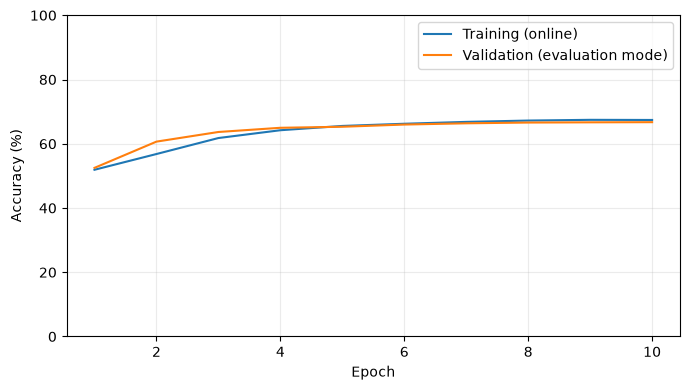

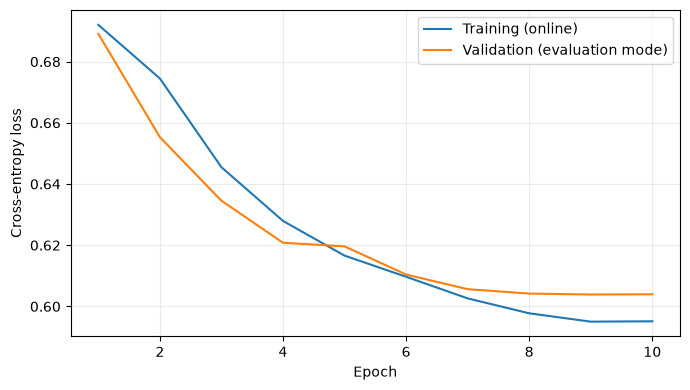

{
  "records": 3000,
  "loss": 0.5916996894826492,
  "accuracy": 0.6826666666666666,
  "balanced_accuracy": 0.6863903272145853,
  "macro_f1": 0.679631567328522,
  "roc_auc": 0.7419135053036514,
  "confusion_matrix": [
    [
      1170,
      283
    ],
    [
      669,
      878
    ]
  ],
  "prediction_counts": [
    1839,
    1161
  ],
  "single_class_predictions": false,
  "classification_report": {
    "PeakBelow83": {
      "precision": 0.636215334420881,
      "recall": 0.805230557467309,
      "f1-score": 0.7108140947752126,
      "support": 1453.0
    },
    "PeakAtOrAbove83": {
      "precision": 0.756244616709733,
      "recall": 0.5675500969618616,
      "f1-score": 0.6484490398818316,
      "support": 1547.0
    },
    "accuracy": 0.6826666666666666,
    "macro avg": {
      "precision": 0.696229975565307,
      "recall": 0.6863903272145853,
      "f1-score": 0.679631567328522,
      "support": 3000.0
    },
    "weighted avg": {
      "precision": 0.6981104343211656,
     

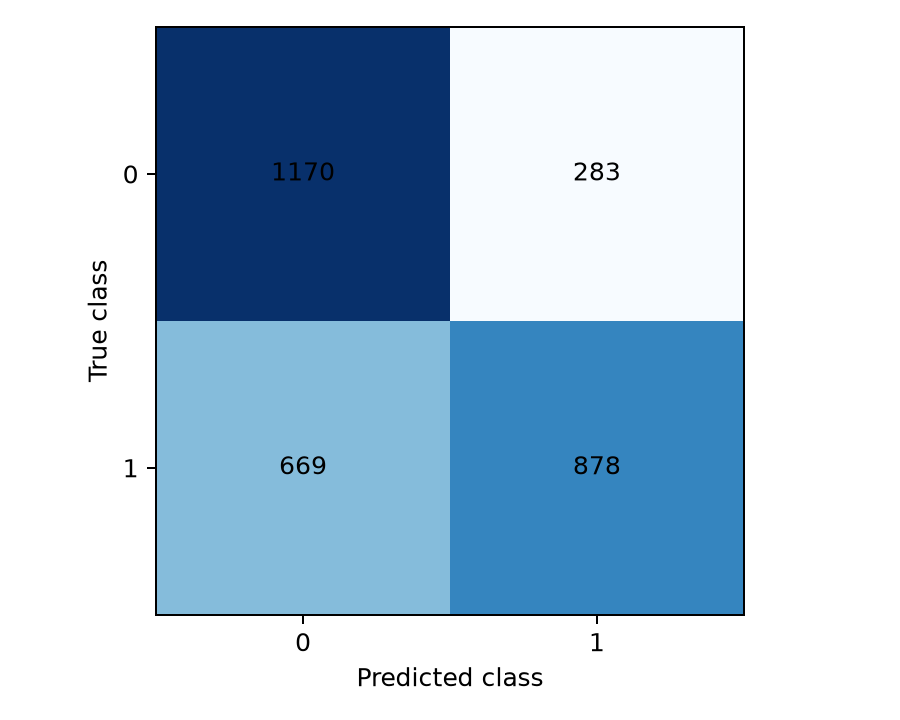

In [20]:
if "result" in globals():
    print("Results:", result["folder"])
    plot_history(result["folder"], show=True)
    if result["test_metrics"] is not None:
        print(json.dumps(result["test_metrics"], indent=2))
        display(Image.open(result["folder"] / "test_confusion_matrix.png"))
